# Chapitre 6 - Cours 2 : rééquilibrer les partitions

Un cluster ne garde pas la même taille toute sa vie : les données et le débit
grossissent, des machines tombent en panne et sont remplacées. Il faut alors **déplacer**
des données d'un nœud à l'autre : c'est le **rééquilibrage**. Ce notebook couvre la
section *Rebalancing Partitions* : *Strategies for Rebalancing* (*How not to do it: hash
mod N*, *Fixed number of partitions*, *Dynamic partitioning*, *Partitioning
proportionally to nodes*), l'encadré *Consistent Hashing* de la section *Partitioning by
Hash of Key*, et *Operations: Automatic or Manual Rebalancing*.

**Plan.**

1. Ce qu'on attend d'un rééquilibrage, et la borne inférieure du volume à déplacer.
2. Ce qu'il ne faut pas faire : haché modulo le nombre de nœuds.
3. Un nombre fixe de partitions, plus nombreuses que les nœuds.
4. Le partitionnement dynamique : des partitions qui se scindent.
5. Des partitions proportionnelles aux nœuds, et le hachage cohérent.
6. Rééquilibrage automatique ou manuel : le risque de cascade.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Wedge

from ddia import partitioning as P
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")
KEYS = np.arange(200_000)                       # 200 000 clés entières pour toutes les mesures

## 1. Ce qu'on attend d'un rééquilibrage (section *Rebalancing Partitions*)

Trois exigences, quelle que soit la stratégie :

1. **après** le rééquilibrage, la charge (données, lectures, écritures) est de nouveau
   répartie équitablement entre les nœuds ;
2. **pendant** le rééquilibrage, la base continue d'accepter lectures et écritures ;
3. on ne déplace **pas plus de données que nécessaire**, pour que l'opération soit rapide
   et ménage le réseau et les disques.

**La borne inférieure.** Passer de $n$ à $n+1$ nœuds équilibrés impose au nouveau venu de
recevoir $1/(n+1)$ des données ; elles viennent forcément d'ailleurs. Aucune stratégie ne
peut donc déplacer moins de $1/(n+1)$ des clés, et une stratégie **optimale** atteint
exactement cette fraction en ne déplaçant **que vers le nouveau nœud** (aucun échange
entre anciens nœuds). Le diagramme montre ce rééquilibrage idéal pour $n = 3$ : chaque
ancien nœud cède un quart de ses données, soit un douzième du total chacun.

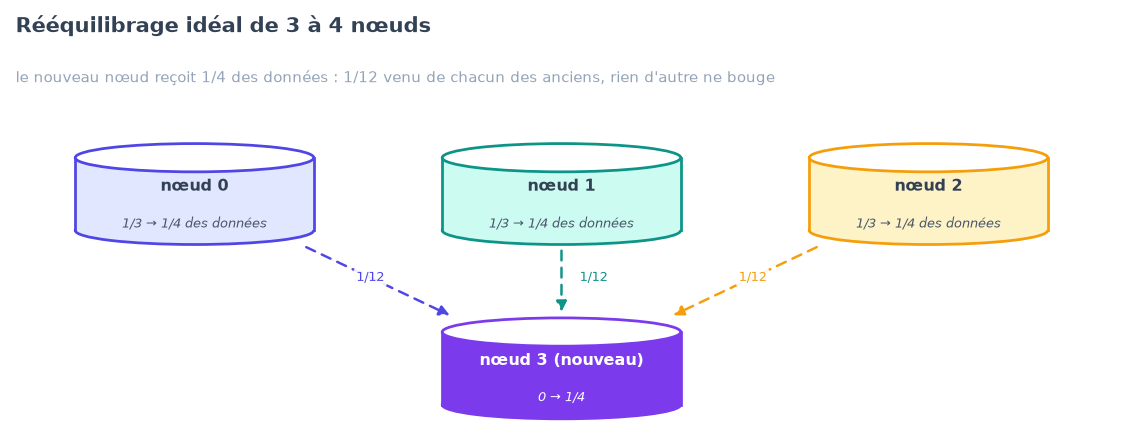

In [2]:
d = Diagram(12, 3.6, title="Rééquilibrage idéal de 3 à 4 nœuds",
            subtitle="le nouveau nœud reçoit 1/4 des données : 1/12 venu de chacun des anciens, rien d'autre ne bouge")
for i, c in enumerate([INDIGO, TEAL, AMBER]):
    d.box(f"n{i}", 2.0 + i * 4.0, 2.55, f"nœud {i}", sub="1/3 → 1/4 des données", color=c, kind="db", w=2.6, h=1.1)
d.box("new", 6.0, 0.65, "nœud 3 (nouveau)", sub="0 → 1/4", color=VIOLET, kind="db", w=2.6, h=1.1, filled=True)
for i, c in enumerate([INDIGO, TEAL, AMBER]):
    d.arrow(f"n{i}", "new", "1/12", color=c, style="dashed", label_pos=0.45, label_offset=(0.35 if i == 1 else 0, 0))
d.show()

Mesurons maintenant chaque stratégie à cette aune : la **fraction de clés déplacées** lors
de l'ajout d'un nœud, comparée à l'optimum $1/(n+1)$.

> **À retenir.** Un bon rééquilibrage rétablit l'équité, ne bloque pas le service et ne
> déplace que le strict nécessaire : au moins $1/(n+1)$ des données quand on passe de $n$
> à $n+1$ nœuds, et rien entre les anciens nœuds.

## 2. Ce qu'il ne faut pas faire : haché modulo N (section *How not to do it: hash mod N*)

La première idée qui vient à l'esprit : nœud $= h(\text{clé}) \bmod N$. Simple, uniforme...
et désastreux au rééquilibrage, car **changer $N$ change le reste de presque toutes les
clés**. La grille ci-dessous montre les hachés 0 à 23 répartis sur 3, 4 puis 5 nœuds ; les
cases cerclées de rose ont changé de nœud par rapport à la ligne du dessus.

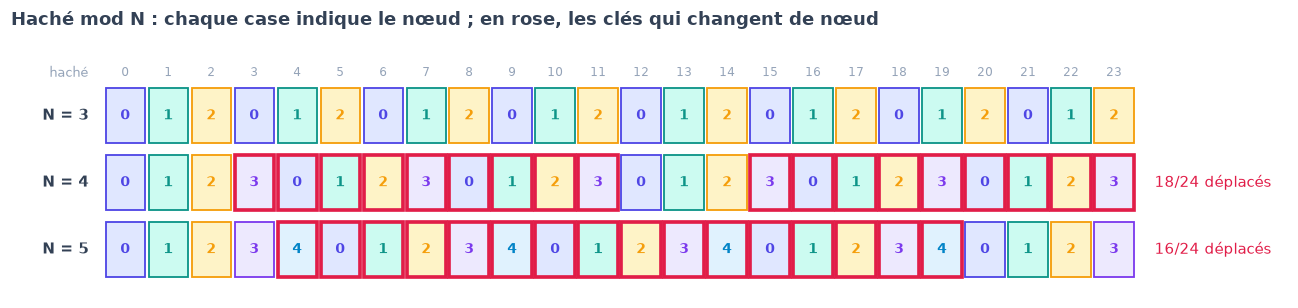

In [3]:
hs = np.arange(24)
fig, ax = plt.subplots(figsize=(12, 2.9))
node_colors = [INDIGO, TEAL, AMBER, VIOLET, SKY]
for r, N in enumerate([3, 4, 5]):
    for h in hs:
        node = h % N
        moved = r > 0 and node != h % (N - 1)
        ax.add_patch(plt.Rectangle((h, -r), 0.92, 0.82, facecolor=LIGHT[node_colors[node]],
                                   edgecolor=ROSE if moved else node_colors[node], lw=2.4 if moved else 1.2))
        ax.text(h + 0.46, -r + 0.41, str(node), ha="center", va="center", fontsize=9,
                color=node_colors[node], fontweight="bold")
    n_moved = sum((h % N) != (h % (N - 1)) for h in hs) if r else 0
    ax.text(-0.4, -r + 0.41, f"N = {N}", ha="right", va="center", fontsize=10, fontweight="bold", color=SLATE)
    if r:
        ax.text(24.4, -r + 0.41, f"{n_moved}/24 déplacés", ha="left", va="center", fontsize=9.5, color=ROSE)
for h in hs:
    ax.text(h + 0.46, 1.05, str(h), ha="center", va="center", fontsize=8, color=GRAY)
ax.text(-0.4, 1.05, "haché", ha="right", va="center", fontsize=8.5, color=GRAY)
ax.set_xlim(-2.2, 27.5); ax.set_ylim(-2.3, 1.4); ax.axis("off")
ax.set_title("Haché mod N : chaque case indique le nœud ; en rose, les clés qui changent de nœud")
plt.tight_layout(); plt.show()

**Pourquoi $N/(N+1)$ ?** Si les hachés sont uniformes, le couple
$(h \bmod N,\ h \bmod (N+1))$ est uniforme sur les $N(N+1)$ couples possibles (théorème
chinois des restes, $N$ et $N+1$ étant premiers entre eux). La clé reste en place si les
deux restes sont égaux : $N$ couples sur $N(N+1)$, soit une probabilité $1/(N+1)$. Elle
**bouge** donc avec probabilité $N/(N+1)$, alors que l'optimum est $1/(N+1)$ : c'est
exactement le contraire de ce qu'on veut. Vérifions par la mesure.

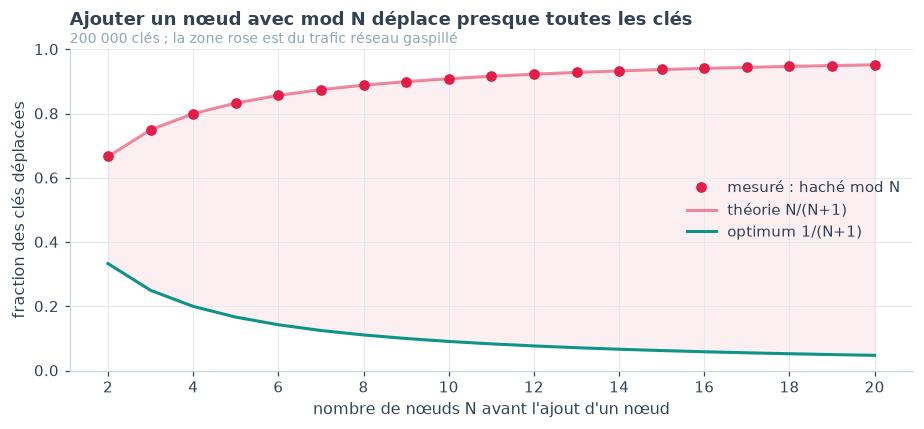

de 10 à 11 nœuds : 90.8% des clés bougent, contre 9.1% au minimum


In [4]:
Ns = np.arange(2, 21)
mod_moved = [P.moved_fraction(P.mod_n_assign(KEYS, N), P.mod_n_assign(KEYS, N + 1)) for N in Ns]
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(Ns, mod_moved, "o", color=ROSE, label="mesuré : haché mod N")
ax.plot(Ns, Ns / (Ns + 1), "-", color=ROSE, alpha=0.5, label="théorie N/(N+1)")
ax.plot(Ns, 1 / (Ns + 1), "-", color=TEAL, label="optimum 1/(N+1)")
ax.fill_between(Ns, 1 / (Ns + 1), Ns / (Ns + 1), color=ROSE, alpha=0.07)
ax.set_xlabel("nombre de nœuds N avant l'ajout d'un nœud"); ax.set_ylabel("fraction des clés déplacées")
ax.set_ylim(0, 1); ax.set_xticks(Ns[::2])
ax.set_title("Ajouter un nœud avec mod N déplace presque toutes les clés")
subtitle(ax, "200 000 clés ; la zone rose est du trafic réseau gaspillé")
ax.legend(loc="center right")
plt.tight_layout(); plt.show()
print(f"de 10 à 11 nœuds : {mod_moved[8]:.1%} des clés bougent, contre {1 / 11:.1%} au minimum")

Passer de 10 à 11 nœuds déplace 91 % des clés, dix fois le nécessaire : sur un cluster de
50 To, cela fait 45 To à transférer au lieu de 4,5.

> **À retenir.** Haché mod N déplace une fraction $N/(N+1)$ des clés à chaque changement de
> taille : il faut découpler « clé → morceau » de « morceau → nœud ».